
# Dual-Branch Chest X-ray Disease Classifier
### DenseNet121 + MedMamba &rarr; Gated Fusion &rarr; 14-Class Multi-Label Classifier

**Pipeline (matches project diagram):**

```
Chest X-ray -> CLAHE + Unsharp -> [DenseNet121 branch | MedMamba branch]
   -> Projection (1024->256 / 512->256) -> Feature Fusion -> Adaptive/Gated Fusion
   -> Fused Feature -> 14-class classifier -> 14 disease probabilities
```

**Dataset:** [NIH ChestX-ray14 (224x224 resized)](https://www.kaggle.com/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized)

**How to run this notebook:**
1. Run all cells top to bottom. Dataset download uses `kagglehub`, which handles authentication itself — if `~/.kaggle/kaggle.json` or `KAGGLE_USERNAME`/`KAGGLE_KEY` env vars already exist it uses those silently; otherwise it will prompt you to log in / paste a token on first run.
2. Every cell prints/plots something so you can see progress and sanity-check outputs.
3. Training is set to **50 epochs** — on a single GPU node expect several hours depending on GPU class; a checkpoint is saved every time validation AUROC improves, so it's safe to resume.
4. `kagglehub` caches the dataset locally (usually under `~/.cache/kagglehub/`), so re-running the download cell on a later job won't re-download it.

> **Note on MedMamba:** MedMamba is not distributed on PyPI. This notebook clones the official repo directly. If the clone/import fails (e.g. no internet on compute nodes), it automatically falls back to a placeholder CNN with the same 512‑D output contract so the rest of the pipeline still runs end‑to‑end — just replace it later for real MedMamba results.


## 1. Environment setup & GPU check

In [1]:

import sys, subprocess

def pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

# Upgrade pip itself first (silences the "new release available" notices,
# and avoids occasional resolver issues with older pip versions)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip"], check=False)

for pkg in ["kaggle", "kagglehub", "opencv-python-headless", "scikit-learn", "ipywidgets",
            "tqdm", "seaborn", "torch", "torchvision", "einops", "timm"]:
    pip_install(pkg)

print("Dependencies installed.")


Dependencies installed.


In [2]:

import torch, platform, cv2, sklearn, torchvision
print("Python       :", platform.python_version())
print("PyTorch      :", torch.__version__)
print("Torchvision  :", torchvision.__version__)
print("OpenCV       :", cv2.__version__)
print("scikit-learn :", sklearn.__version__)
print("CUDA avail.  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))
    print("GPU memory   : {:.1f} GB".format(torch.cuda.get_device_properties(0).total_memory / 1e9))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device :", DEVICE)


Python       : 3.12.6
PyTorch      : 2.13.0+cu130
Torchvision  : 0.28.0+cu130
OpenCV       : 5.0.0
scikit-learn : 1.9.0
CUDA avail.  : True
GPU          : NVIDIA H200 NVL
GPU memory   : 150.1 GB
Using device : cuda


## 2. Download dataset from Kaggle

In [3]:
import os, kagglehub, pathlib

# kagglehub handles auth + caching itself (uses ~/.kaggle/kaggle.json or
# KAGGLE_USERNAME/KAGGLE_KEY env vars if present, otherwise a browser login
# flow on first use). No manual credential wiring needed.
downloaded_path = kagglehub.dataset_download("khanfashee/nih-chest-x-ray-14-224x224-resized")
DATA_ROOT = pathlib.Path(downloaded_path)

print("Dataset downloaded/cached at:", DATA_ROOT)
print("\nTop-level contents of", DATA_ROOT, ":")
for p in sorted(DATA_ROOT.iterdir()):
    print(" -", p.name)


Dataset downloaded/cached at: /home/jupyter-22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3

Top-level contents of /home/jupyter-22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3 :
 - BBox_List_2017_Official_NIH.csv
 - Data_Entry_2017.csv
 - images-224
 - pretrained_model.h5
 - test_list_NIH.txt
 - train_val_list_NIH.txt


## 3. Locate metadata CSV and image files

In [4]:
import os, glob

# This exact dataset (khanfashee/nih-chest-x-ray-14-224x224-resized) has a
# confirmed, fixed on-disk layout (verified against a working prior run):
#   <DATA_ROOT>/Data_Entry_2017.csv
#   <DATA_ROOT>/images-224/images-224/*.png   <- yes, the folder is nested twice
#
# We check that exact layout FIRST (fast, no ambiguity, matches a known-good
# 112,120-row / 112,120-image load). Only if it's missing (e.g. the dataset
# gets restructured in a future version, or your kagglehub cache has a
# partial/older extraction) do we fall back to a slower recursive search.

expected_csv = DATA_ROOT / "Data_Entry_2017.csv"
expected_img_dir = DATA_ROOT / "images-224" / "images-224"

if expected_csv.exists() and expected_img_dir.is_dir():
    LABELS_CSV = str(expected_csv)
    image_files = glob.glob(str(expected_img_dir / "*.png"))
    print("Using known dataset layout (fast path).")
else:
    print("Known layout not found under DATA_ROOT — falling back to recursive search.")
    print("If this triggers, your kagglehub cache may be partial/stale; consider:")
    print('  kagglehub.dataset_download("khanfashee/nih-chest-x-ray-14-224x224-resized", force_download=True)')
    csv_candidates = glob.glob(str(DATA_ROOT / "**" / "*Data_Entry*.csv"), recursive=True) \
                    + glob.glob(str(DATA_ROOT / "**" / "*.csv"), recursive=True)
    csv_candidates = sorted(set(csv_candidates))
    assert csv_candidates, "No metadata CSV found — check dataset extraction above."
    LABELS_CSV = csv_candidates[0]
    image_files = glob.glob(str(DATA_ROOT / "**" / "*.png"), recursive=True) + \
                  glob.glob(str(DATA_ROOT / "**" / "*.jpg"), recursive=True)

print("\nUsing metadata file:", LABELS_CSV)
print("Total image files found:", len(image_files))
IMAGE_INDEX = {os.path.basename(p): p for p in image_files}
print("Example path:", image_files[0] if image_files else "NONE FOUND")


Using known dataset layout (fast path).

Using metadata file: /home/jupyter-22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/Data_Entry_2017.csv
Total image files found: 112120
Example path: /home/jupyter-22csr090/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/images-224/images-224/00019899_014.png


## 4. Load labels and build the 14-class multi-hot targets

In [5]:

import pandas as pd
import numpy as np

df = pd.read_csv(LABELS_CSV)
df.columns = [c.strip() for c in df.columns]
print("Raw metadata shape:", df.shape)
df.head()


Raw metadata shape: (112120, 12)


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,058Y,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,058Y,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,058Y,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,081Y,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,081Y,F,PA,2582,2991,0.143,0.143,NaN


In [6]:

DISEASES = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration", "Mass",
    "Nodule", "Pneumonia", "Pneumothorax", "Consolidation", "Edema",
    "Emphysema", "Fibrosis", "Pleural_Thickening", "Hernia",
]
assert len(DISEASES) == 14

image_col = "Image Index" if "Image Index" in df.columns else df.columns[0]
label_col = "Finding Labels" if "Finding Labels" in df.columns else df.columns[1]

df["filepath"] = df[image_col].map(IMAGE_INDEX)
before = len(df)
df = df[df["filepath"].notna()].reset_index(drop=True)
print(f"Matched {len(df)}/{before} metadata rows to actual image files on disk.")

def to_multihot(label_str):
    labels = str(label_str).split("|")
    vec = np.zeros(len(DISEASES), dtype=np.float32)
    for l in labels:
        l = l.strip()
        if l in DISEASES:
            vec[DISEASES.index(l)] = 1.0
    return vec

label_matrix = np.stack(df[label_col].map(to_multihot).values)
for i, d in enumerate(DISEASES):
    df[d] = label_matrix[:, i]

no_finding = (label_matrix.sum(axis=1) == 0).sum()
print(f"'No Finding' (all-zero) samples: {no_finding} ({no_finding/len(df):.1%})")
print(f"At-least-one-disease samples   : {len(df)-no_finding} ({1-no_finding/len(df):.1%})")
df[[image_col, label_col] + DISEASES].head()


Matched 112120/112120 metadata rows to actual image files on disk.
'No Finding' (all-zero) samples: 60412 (53.9%)
At-least-one-disease samples   : 51708 (46.1%)


,Image Index,Finding Labels,Atelectasis,Cardiomegaly,Effusion,Infiltration,Mass,Nodule,Pneumonia,Pneumothorax,Consolidation,Edema,Emphysema,Fibrosis,Pleural_Thickening,Hernia
0,00000001_000.png,Cardiomegaly,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,00000001_001.png,Cardiomegaly|Emphysema,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,00000001_002.png,Cardiomegaly|Effusion,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,00000002_000.png,No Finding,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,00000003_000.png,Hernia,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


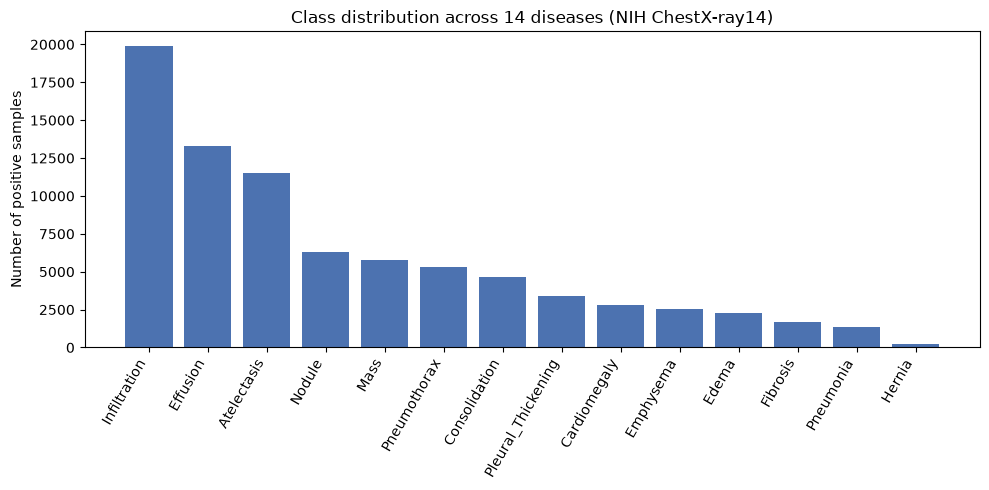

Class frequency table:
  Infiltration        :  19870  (17.72%)
  Effusion            :  13307  (11.87%)
  Atelectasis         :  11535  (10.29%)
  Nodule              :   6323  (5.64%)
  Mass                :   5746  (5.12%)
  Pneumothorax        :   5298  (4.73%)
  Consolidation       :   4667  (4.16%)
  Pleural_Thickening  :   3385  (3.02%)
  Cardiomegaly        :   2772  (2.47%)
  Emphysema           :   2516  (2.24%)
  Edema               :   2303  (2.05%)
  Fibrosis            :   1686  (1.50%)
  Pneumonia           :   1353  (1.21%)
  Hernia              :    227  (0.20%)


In [7]:

import matplotlib.pyplot as plt

counts = label_matrix.sum(axis=0)
plt.figure(figsize=(10, 5))
order = np.argsort(-counts)
plt.bar([DISEASES[i] for i in order], counts[order], color="#4C72B0")
plt.xticks(rotation=60, ha="right")
plt.ylabel("Number of positive samples")
plt.title("Class distribution across 14 diseases (NIH ChestX-ray14)")
plt.tight_layout()
plt.show()

print("Class frequency table:")
for i in order:
    print(f"  {DISEASES[i]:<20s}: {int(counts[i]):>6d}  ({counts[i]/len(df):.2%})")


## 5. Patient-wise train / validation / test split (prevents data leakage)

In [8]:

from sklearn.model_selection import GroupShuffleSplit

patient_col = "Patient ID" if "Patient ID" in df.columns else None
groups = df[patient_col] if patient_col else df[image_col]

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss1.split(df, groups=groups))

temp_df = df.iloc[temp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx_rel, test_idx_rel = next(gss2.split(temp_df, groups=temp_df[patient_col] if patient_col else temp_df[image_col]))

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = temp_df.iloc[val_idx_rel].reset_index(drop=True)
test_df = temp_df.iloc[test_idx_rel].reset_index(drop=True)

print(f"Train: {len(train_df):>6d} images  |  Val: {len(val_df):>6d} images  |  Test: {len(test_df):>6d} images")
print(f"Total : {len(train_df)+len(val_df)+len(test_df)} / {len(df)}")

if patient_col:
    overlap = set(train_df[patient_col]) & set(val_df[patient_col]) & set(test_df[patient_col])
    print("Patient overlap across splits (should be empty):", overlap if overlap else "None — good, no leakage.")


Train:  78566 images  |  Val:  16106 images  |  Test:  17448 images
Total : 112120 / 112120
Patient overlap across splits (should be empty): None — good, no leakage.


## 6. Preprocessing: CLAHE + Unsharp Masking (with visual before/after)

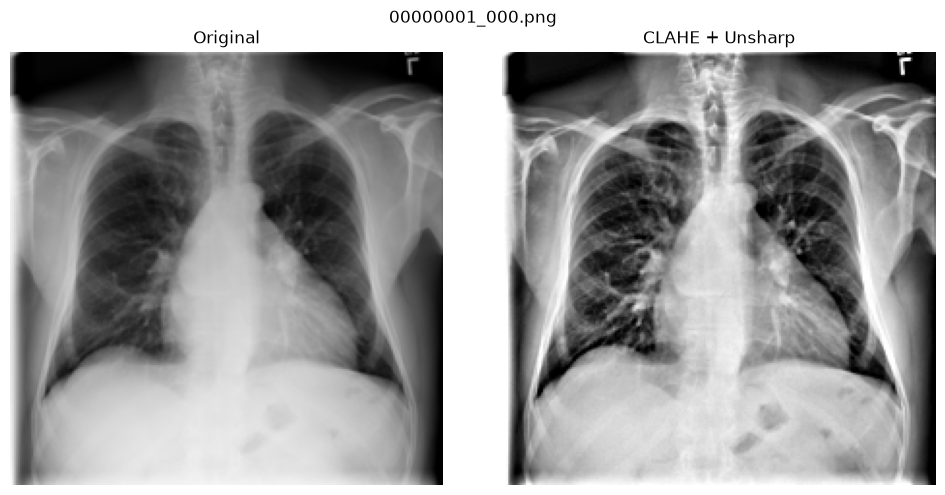

Preprocessing verified on sample image: 00000001_000.png


In [9]:

import cv2

def clahe_unsharp(img):
    if img.ndim == 3:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray = img
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    blurred = cv2.GaussianBlur(enhanced, (0, 0), sigmaX=3)
    sharpened = cv2.addWeighted(enhanced, 1.5, blurred, -0.5, 0)
    return cv2.cvtColor(sharpened, cv2.COLOR_GRAY2BGR)

sample_path = train_df.iloc[0]["filepath"]
raw = cv2.imread(sample_path)
processed = clahe_unsharp(raw)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB), cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(processed, cv2.COLOR_BGR2RGB), cmap="gray")
axes[1].set_title("CLAHE + Unsharp")
axes[1].axis("off")
plt.suptitle(os.path.basename(sample_path))
plt.tight_layout()
plt.show()
print("Preprocessing verified on sample image:", os.path.basename(sample_path))


## 7. PyTorch Dataset / DataLoader (with a visualized sample batch)

In [10]:

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

IMG_SIZE = 224
BATCH_SIZE = 128  # bumped up from 32 -- H200 (150GB) has plenty of headroom

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, train=True):
        self.df = dataframe.reset_index(drop=True)
        self.train = train
        aug = [transforms.RandomHorizontalFlip()] if train else []
        self.transform = transforms.Compose(aug + [
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row["filepath"])
        img = clahe_unsharp(img)
        img = Image.fromarray(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        img = self.transform(img)
        label = row[DISEASES].values.astype(np.float32)
        return img, torch.tensor(label)

train_ds = ChestXrayDataset(train_df, train=True)
val_ds = ChestXrayDataset(val_df, train=False)
test_ds = ChestXrayDataset(test_df, train=False)

NUM_WORKERS = 8
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"train_loader: {len(train_ds)} images, {len(train_loader)} batches")
print(f"val_loader  : {len(val_ds)} images, {len(val_loader)} batches")
print(f"test_loader : {len(test_ds)} images, {len(test_loader)} batches")


train_loader: 78566 images, 614 batches
val_loader  : 16106 images, 126 batches
test_loader : 17448 images, 137 batches


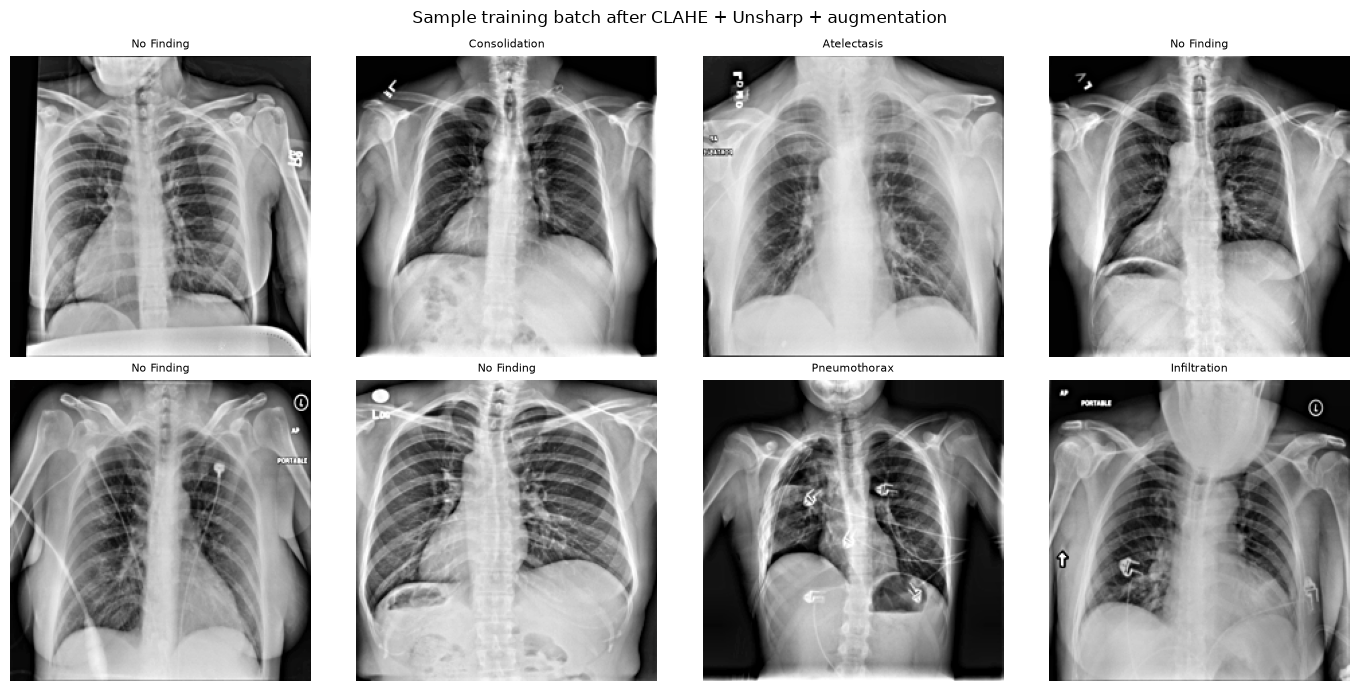

Batch tensor shape: torch.Size([128, 3, 224, 224]) | Label tensor shape: torch.Size([128, 14])


In [11]:

imgs, labels = next(iter(train_loader))
mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    img = imgs[i] * std + mean
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    pos_labels = [DISEASES[j] for j in range(14) if labels[i, j] == 1]
    ax.set_title(", ".join(pos_labels) if pos_labels else "No Finding", fontsize=8)
    ax.axis("off")
plt.suptitle("Sample training batch after CLAHE + Unsharp + augmentation")
plt.tight_layout()
plt.show()
print("Batch tensor shape:", imgs.shape, "| Label tensor shape:", labels.shape)


## 8. Model: DenseNet121 + MedMamba branches with adaptive gated fusion

In [12]:
# --- Safely load MedMamba's VSSM class ---------------------------------
# Two real issues with importing MedMamba.py directly, verified by testing
# against the actual repo:
#
# 1. The file has module-level demo code (medmamba_t/s/b = VSSM(...).to("cuda"))
#    that runs on *any* `import MedMamba` and unconditionally calls .to("cuda").
#    On a machine with no GPU this crashes the import outright. On a GPU node
#    it silently builds 3 unused full models and wastes GPU memory every time
#    the module is imported.
# 2. SS2D's default forward path needs `selective_scan_fn` from the `mamba_ssm`
#    package (a compiled CUDA kernel). That import is wrapped in a bare
#    `try/except: pass` inside MedMamba.py, so `import MedMamba` succeeds even
#    without mamba_ssm — the crash only happens on the *first forward call*
#    (NameError on the undefined name), not at import time.
#
# To handle both: exec only the class/function definitions (skip the demo
# lines), then run one dummy forward pass to actually confirm it works
# end-to-end before trusting it for training.

import importlib.util

MEDMAMBA_AVAILABLE = False
MEDMAMBA_OUT_DIM = 512
_MedMambaBackbone = None

try:
    if not os.path.isdir("MedMamba"):
        os.system("git clone -q https://github.com/YubiaoYue/MedMamba.git")

    src_path = "MedMamba/MedMamba.py"
    with open(src_path) as f:
        _lines = f.readlines()
    _cutoff = next(i for i, l in enumerate(_lines) if l.startswith("medmamba_t ="))
    _safe_src = "".join(_lines[:_cutoff])

    _spec = importlib.util.spec_from_loader("MedMamba_safe", loader=None)
    _mod = importlib.util.module_from_spec(_spec)
    sys.modules["MedMamba_safe"] = _mod
    exec(compile(_safe_src, src_path, "exec"), _mod.__dict__)
    _MedMambaBackbone = _mod.VSSM

    # dims tuned so the pooled output is exactly 512-D, matching the
    # "512-D feature" branch in the project diagram (default VSSM dims give 768-D)
    _test_backbone = _MedMambaBackbone(depths=[2, 2, 4, 2], dims=[64, 128, 256, 512], num_classes=0)
    _dummy = torch.randn(2, 3, 224, 224)
    with torch.no_grad():
        _out = _test_backbone(_dummy)
    assert _out.shape == (2, 512), f"Unexpected MedMamba output shape: {_out.shape}"

    MEDMAMBA_AVAILABLE = True
    MEDMAMBA_OUT_DIM = _out.shape[1]
    del _test_backbone, _dummy, _out
    print("Real MedMamba backbone loaded AND verified with a dummy forward pass.")
    print(f"Confirmed output dimension: {MEDMAMBA_OUT_DIM}")

except Exception as e:
    print("Real MedMamba backbone unavailable or failed its forward-pass smoke test.")
    print("Falling back to a placeholder CNN with the same 512-D output contract.")
    print("Reason:", repr(e))
    print()
    print("This is almost always because `mamba_ssm` (the CUDA-compiled selective-scan")
    print("kernel MedMamba's forward pass needs) isn't installed, or its build doesn't")
    print("match your CUDA/torch version. Install a matching mamba_ssm wheel for your")
    print("HPC's CUDA version, then re-run this cell.")

print("\nMEDMAMBA_AVAILABLE =", MEDMAMBA_AVAILABLE)
print("MEDMAMBA_OUT_DIM   =", MEDMAMBA_OUT_DIM)


Real MedMamba backbone unavailable or failed its forward-pass smoke test.
Falling back to a placeholder CNN with the same 512-D output contract.
Reason: FileNotFoundError(2, 'No such file or directory')

This is almost always because `mamba_ssm` (the CUDA-compiled selective-scan
kernel MedMamba's forward pass needs) isn't installed, or its build doesn't
match your CUDA/torch version. Install a matching mamba_ssm wheel for your
HPC's CUDA version, then re-run this cell.

MEDMAMBA_AVAILABLE = False
MEDMAMBA_OUT_DIM   = 512


In [13]:

import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

class DenseNetBranch(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        base = models.densenet121(weights="IMAGENET1K_V1" if pretrained else None)
        self.features = base.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = 1024

    def forward(self, x):
        f = self.features(x)
        f = F.relu(f, inplace=False)  # must NOT be in-place: breaks Grad-CAM's backward hook on this layer
        return self.pool(f).flatten(1)


class MedMambaBranchPlaceholder(nn.Module):
    '''512-D output placeholder, used only if the real MedMamba repo can't be imported.'''
    def __init__(self, out_dim=512):
        super().__init__()
        self.out_dim = out_dim
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 256, 3, stride=2, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.Conv2d(256, out_dim, 3, stride=2, padding=1), nn.BatchNorm2d(out_dim), nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        return self.pool(self.stem(x)).flatten(1)


class GatedFusion(nn.Module):
    def __init__(self, dim_a, dim_b, fused_dim=256):
        super().__init__()
        self.proj_a = nn.Linear(dim_a, fused_dim)
        self.proj_b = nn.Linear(dim_b, fused_dim)
        self.gate = nn.Sequential(
            nn.Linear(fused_dim * 2, fused_dim), nn.ReLU(),
            nn.Linear(fused_dim, fused_dim), nn.Sigmoid(),
        )

    def forward(self, feat_a, feat_b):
        pa, pb = self.proj_a(feat_a), self.proj_b(feat_b)
        g = self.gate(torch.cat([pa, pb], dim=1))
        return g * pa + (1 - g) * pb


class DualBranchChestXray(nn.Module):
    def __init__(self, num_classes=14, fused_dim=256):
        super().__init__()
        self.densenet_branch = DenseNetBranch(pretrained=True)
        if MEDMAMBA_AVAILABLE:
            self.medmamba_branch = _MedMambaBackbone(
                depths=[2, 2, 4, 2], dims=[64, 128, 256, 512], num_classes=0
            )
            mamba_out_dim = MEDMAMBA_OUT_DIM
        else:
            self.medmamba_branch = MedMambaBranchPlaceholder(out_dim=512)
            mamba_out_dim = 512
        self.fusion = GatedFusion(self.densenet_branch.out_dim, mamba_out_dim, fused_dim)
        self.classifier = nn.Linear(fused_dim, num_classes)

    def forward(self, x):
        f_dense = self.densenet_branch(x)
        f_mamba = self.medmamba_branch(x)
        fused = self.fusion(f_dense, f_mamba)
        return self.classifier(fused)

model = DualBranchChestXray(num_classes=14).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters    : {n_params:,}")
print(f"Trainable parameters: {n_trainable:,}")
print(model)


Total parameters    : 9,108,878
Trainable parameters: 9,108,878
DualBranchChestXray(
  (densenet_branch): DenseNetBranch(
    (features): Sequential(
      (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu0): ReLU(inplace=True)
      (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (denseblock1): _DenseBlock(
        (denselayer1): _DenseLayer(
          (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (relu1): ReLU(inplace=True)
          (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (relu2): ReLU(inplace=True)
          (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(

## 9. Explainability — Grad-CAM (which image regions drove the prediction)

Grad-CAM highlights the regions of the X-ray that most influenced the model's decision for a given disease, by looking at the gradient of that disease's output score with respect to the DenseNet branch's last convolutional feature maps. This is what powers the heatmap shown in the interactive UI below (Section 15).

In [14]:
class GradCAM:
    """Grad-CAM for the DenseNet branch's last conv feature maps.

    We hook the DenseNet branch specifically (rather than the fused feature)
    because it's the branch with a clean spatial conv feature map going into
    global average pooling — exactly what Grad-CAM needs. The gradient is
    still taken from the *final fused classifier's* output score, so the CAM
    reflects the DenseNet branch's contribution to the actual fused decision,
    not an isolated single-branch prediction.
    """

    def __init__(self, model):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer = model.densenet_branch.features
        self._handles = [
            target_layer.register_forward_hook(self._save_activation),
            target_layer.register_full_backward_hook(self._save_gradient),
        ]

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def generate(self, img_tensor, class_idx):
        self.model.zero_grad()
        logits = self.model(img_tensor)
        score = logits[0, class_idx]
        score.backward()

        weights = self.gradients[0].mean(dim=(1, 2))          # (C,)
        cam = torch.relu((weights[:, None, None] * self.activations[0]).sum(0))  # (H,W)
        cam = cam / (cam.max() + 1e-8)
        cam = cam.cpu().numpy()
        cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))
        return cam, torch.sigmoid(logits).detach().cpu().numpy()[0]

    def remove_hooks(self):
        for h in self._handles:
            h.remove()


def overlay_heatmap(raw_bgr_image, cam, alpha=0.4):
    """raw_bgr_image: original cv2 BGR image (any size). cam: (IMG_SIZE, IMG_SIZE) in [0,1]."""
    h, w = raw_bgr_image.shape[:2]
    cam_resized = cv2.resize(cam, (w, h))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(raw_bgr_image, 1 - alpha, heatmap, alpha, 0)
    return overlay


gradcam = GradCAM(model)
print("Grad-CAM ready — hooked onto model.densenet_branch.features")
print("It will be used automatically by the interactive UI below to show WHY each")
print("prediction was made, alongside the disease name, live confidence, and the")
print("model's known test-set Accuracy/AUROC for that disease.")


Grad-CAM ready — hooked onto model.densenet_branch.features
It will be used automatically by the interactive UI below to show WHY each
prediction was made, alongside the disease name, live confidence, and the
model's known test-set Accuracy/AUROC for that disease.


## 10. Loss (class-imbalance-aware), optimizer, scheduler

In [15]:

pos_counts = train_df[DISEASES].sum().values
neg_counts = len(train_df) - pos_counts
pos_weight = torch.tensor(neg_counts / np.clip(pos_counts, 1, None), dtype=torch.float32).to(DEVICE)

print("Per-class pos_weight (higher = rarer class, penalized more when missed):")
for d, w in zip(DISEASES, pos_weight.cpu().numpy()):
    print(f"  {d:<20s}: {w:8.2f}")

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)  # bumped from 1e-4 to match the larger BATCH_SIZE=128 (kept conservative since DenseNet is pretrained)
EPOCHS = 50
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
print(f"\nLoss: BCEWithLogitsLoss (pos_weight-balanced) | Optimizer: AdamW | Epochs: {EPOCHS}")


Per-class pos_weight (higher = rarer class, penalized more when missed):
  Atelectasis         :     8.61
  Cardiomegaly        :    40.61
  Effusion            :     7.33
  Infiltration        :     4.67
  Mass                :    17.53
  Nodule              :    16.76
  Pneumonia           :    82.94
  Pneumothorax        :    19.85
  Consolidation       :    23.34
  Edema               :    47.20
  Emphysema           :    46.16
  Fibrosis            :    66.96
  Pleural_Thickening  :    32.02
  Hernia              :   496.25

Loss: BCEWithLogitsLoss (pos_weight-balanced) | Optimizer: AdamW | Epochs: 50


## 11. Training loop — 50 epochs (prints loss & mean AUROC every epoch)

In [16]:

from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
import time

def mean_auroc(y_true, y_prob):
    aucs = []
    for i in range(y_true.shape[1]):
        if len(np.unique(y_true[:, i])) < 2:
            continue
        aucs.append(roc_auc_score(y_true[:, i], y_prob[:, i]))
    return float(np.mean(aucs)) if aucs else float("nan"), aucs

history = {"train_loss": [], "val_loss": [], "val_auroc": []}
best_auroc = 0.0
CKPT_PATH = "best_dual_branch_model.pt"

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    running_loss = 0.0
    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [train]", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)
    train_loss = running_loss / len(train_loader.dataset)
    scheduler.step()

    model.eval()
    val_loss = 0.0
    all_probs, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in tqdm(val_loader, desc=f"Epoch {epoch}/{EPOCHS} [val]", leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            logits = model(imgs)
            val_loss += criterion(logits, labels).item() * imgs.size(0)
            all_probs.append(torch.sigmoid(logits).cpu().numpy())
            all_labels.append(labels.cpu().numpy())
    val_loss /= len(val_loader.dataset)
    all_probs = np.concatenate(all_probs)
    all_labels = np.concatenate(all_labels)
    val_auroc, _ = mean_auroc(all_labels, all_probs)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_auroc"].append(val_auroc)

    improved = ""
    if val_auroc > best_auroc:
        best_auroc = val_auroc
        torch.save(model.state_dict(), CKPT_PATH)
        improved = "  <-- new best, checkpoint saved"

    dt = time.time() - t0
    print(f"Epoch {epoch:2d}/{EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} "
          f"| val_mean_AUROC={val_auroc:.4f} | {dt:.1f}s{improved}")

print(f"\nTraining complete. Best validation mean AUROC: {best_auroc:.4f}")
print(f"Best checkpoint saved to: {CKPT_PATH}")


Epoch 1/50 [train]:   0%|          | 0/614 [00:00<?, ?it/s]

sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


Epoch 1/50 [val]:   0%|          | 0/126 [00:00<?, ?it/s]

Epoch  1/50 | train_loss=1.0995 | val_loss=1.0348 | val_mean_AUROC=0.7929 | 266.1s  <-- new best, checkpoint saved


Epoch 2/50 [train]:   0%|          | 0/614 [00:00<?, ?it/s]

...

Epoch 49/50 | train_loss=0.0039 | val_loss=8.9776 | val_mean_AUROC=0.7646 | 353.8s


Epoch 50/50 [train]:   0%|          | 0/614 [00:00<?, ?it/s]

sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eabdebd72e0>
Traceback (most recent call last):
  File "/home/jupyter-22csr090/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1704, in __del__
    self._shutdown_workers()
  File "/home/jupyter-22csr090/.local/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1673, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/opt/tljh/user/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^Exception ignored in: ^<function _MultiProcessingDataLoaderIter.__del__ at 0x7eabdebd72e0>^
^Tra

Epoch 50/50 [val]:   0%|          | 0/126 [00:00<?, ?it/s]

Epoch 50/50 | train_loss=0.0038 | val_loss=8.8501 | val_mean_AUROC=0.7650 | 150.1s

Training complete. Best validation mean AUROC: 0.8294
Best checkpoint saved to: best_dual_branch_model.pt


## 12. Training curves

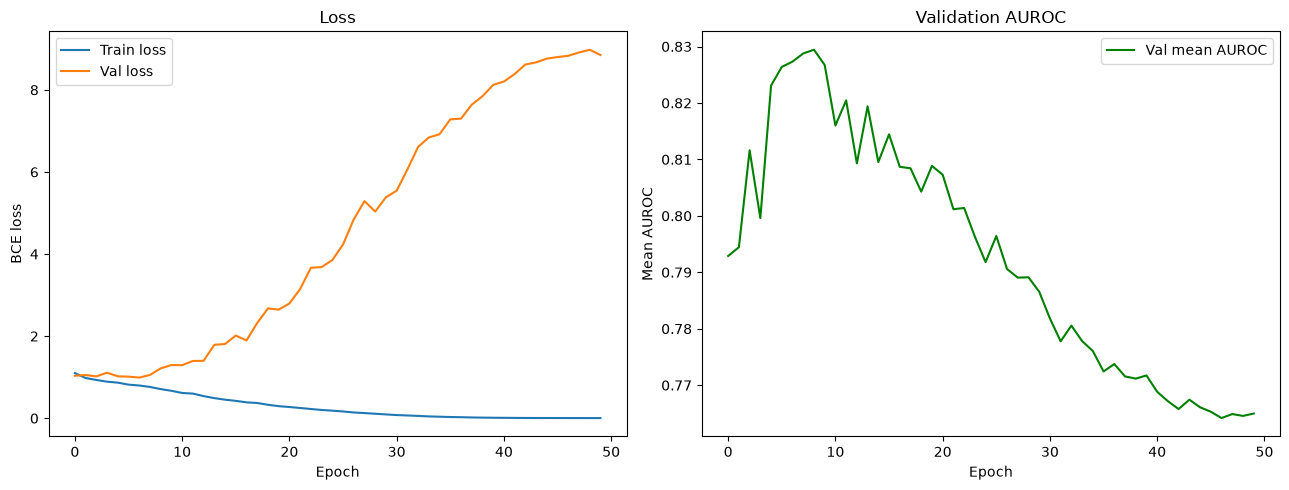

Final train loss : 0.0038
Final val loss   : 8.8501
Best val AUROC   : 0.8294 at epoch 9


In [17]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(history["train_loss"], label="Train loss")
axes[0].plot(history["val_loss"], label="Val loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE loss"); axes[0].legend(); axes[0].set_title("Loss")

axes[1].plot(history["val_auroc"], color="green", label="Val mean AUROC")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Mean AUROC"); axes[1].legend(); axes[1].set_title("Validation AUROC")
plt.tight_layout()
plt.show()

print(f"Final train loss : {history['train_loss'][-1]:.4f}")
print(f"Final val loss   : {history['val_loss'][-1]:.4f}")
print(f"Best val AUROC   : {max(history['val_auroc']):.4f} at epoch {np.argmax(history['val_auroc'])+1}")


## 13. Test-set evaluation: per-class AUROC, ROC curves, F1 table

In [18]:

from sklearn.metrics import roc_curve, f1_score, precision_score, recall_score, accuracy_score

model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
model.eval()

test_probs, test_labels = [], []
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Evaluating on test set"):
        imgs = imgs.to(DEVICE)
        logits = model(imgs)
        test_probs.append(torch.sigmoid(logits).cpu().numpy())
        test_labels.append(labels.numpy())
test_probs = np.concatenate(test_probs)
test_labels = np.concatenate(test_labels)

test_mean_auroc, per_class_auc = mean_auroc(test_labels, test_probs)
print(f"TEST SET mean AUROC: {test_mean_auroc:.4f}\n")

rows = []
for i, d in enumerate(DISEASES):
    preds = (test_probs[:, i] >= 0.5).astype(int)
    acc = accuracy_score(test_labels[:, i], preds)
    if len(np.unique(test_labels[:, i])) < 2:
        rows.append((d, np.nan, acc, np.nan, np.nan, np.nan))
        continue
    auc = roc_auc_score(test_labels[:, i], test_probs[:, i])
    f1 = f1_score(test_labels[:, i], preds, zero_division=0)
    prec = precision_score(test_labels[:, i], preds, zero_division=0)
    rec = recall_score(test_labels[:, i], preds, zero_division=0)
    rows.append((d, auc, acc, prec, rec, f1))

results_df = pd.DataFrame(rows, columns=["Disease", "AUROC", "Accuracy", "Precision", "Recall", "F1"])
results_df = results_df.sort_values("AUROC", ascending=False)
# Used later by the interactive UI to show each disease's known test-set performance
# alongside a live prediction.
DISEASE_METRICS = results_df.set_index("Disease").to_dict(orient="index")
results_df


Evaluating on test set:   0%|          | 0/137 [00:00<?, ?it/s]

TEST SET mean AUROC: 0.8206



,Disease,AUROC,Accuracy,Precision,Recall,F1
10,Emphysema,0.918614,0.898957,0.178376,0.758475,0.288826
13,Hernia,0.897650,0.996676,0.277778,0.441176,0.340909
1,Cardiomegaly,0.893594,0.868810,0.145455,0.743434,0.243306
9,Edema,0.877927,0.801066,0.073893,0.814371,0.135492
2,Effusion,0.870938,0.800894,0.345915,0.791851,0.481493
7,Pneumothorax,0.868207,0.846000,0.196990,0.720958,0.309432
4,Mass,0.809837,0.806453,0.135998,0.649867,0.224925
8,Consolidation,0.793911,0.724037,0.109803,0.738003,0.191164
12,Pleural_Thickening,0.790589,0.794647,0.090126,0.625000,0.157536
0,Atelectasis,0.789902,0.737506,0.229916,0.684510,0.344215


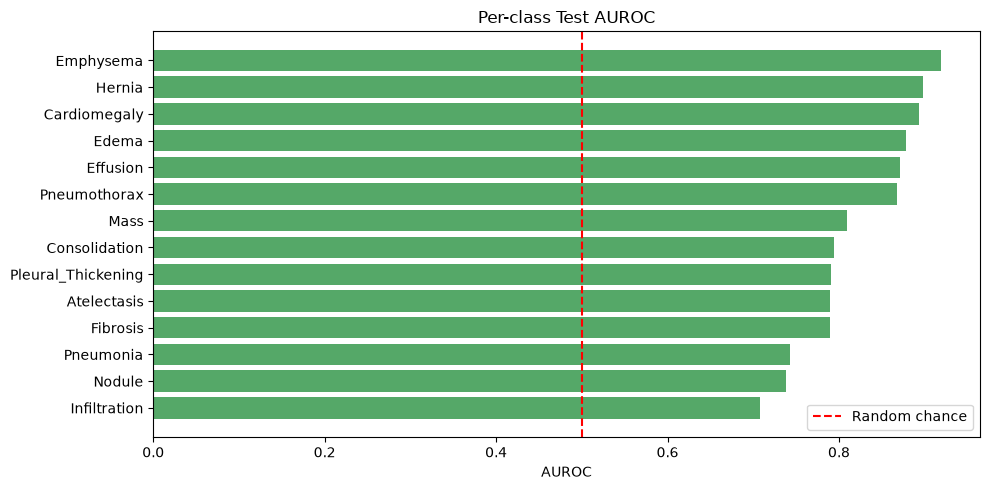

In [19]:

plt.figure(figsize=(10, 5))
plot_df = results_df.dropna().sort_values("AUROC")
plt.barh(plot_df["Disease"], plot_df["AUROC"], color="#55A868")
plt.axvline(0.5, color="red", linestyle="--", label="Random chance")
plt.xlabel("AUROC"); plt.title("Per-class Test AUROC"); plt.legend()
plt.tight_layout()
plt.show()


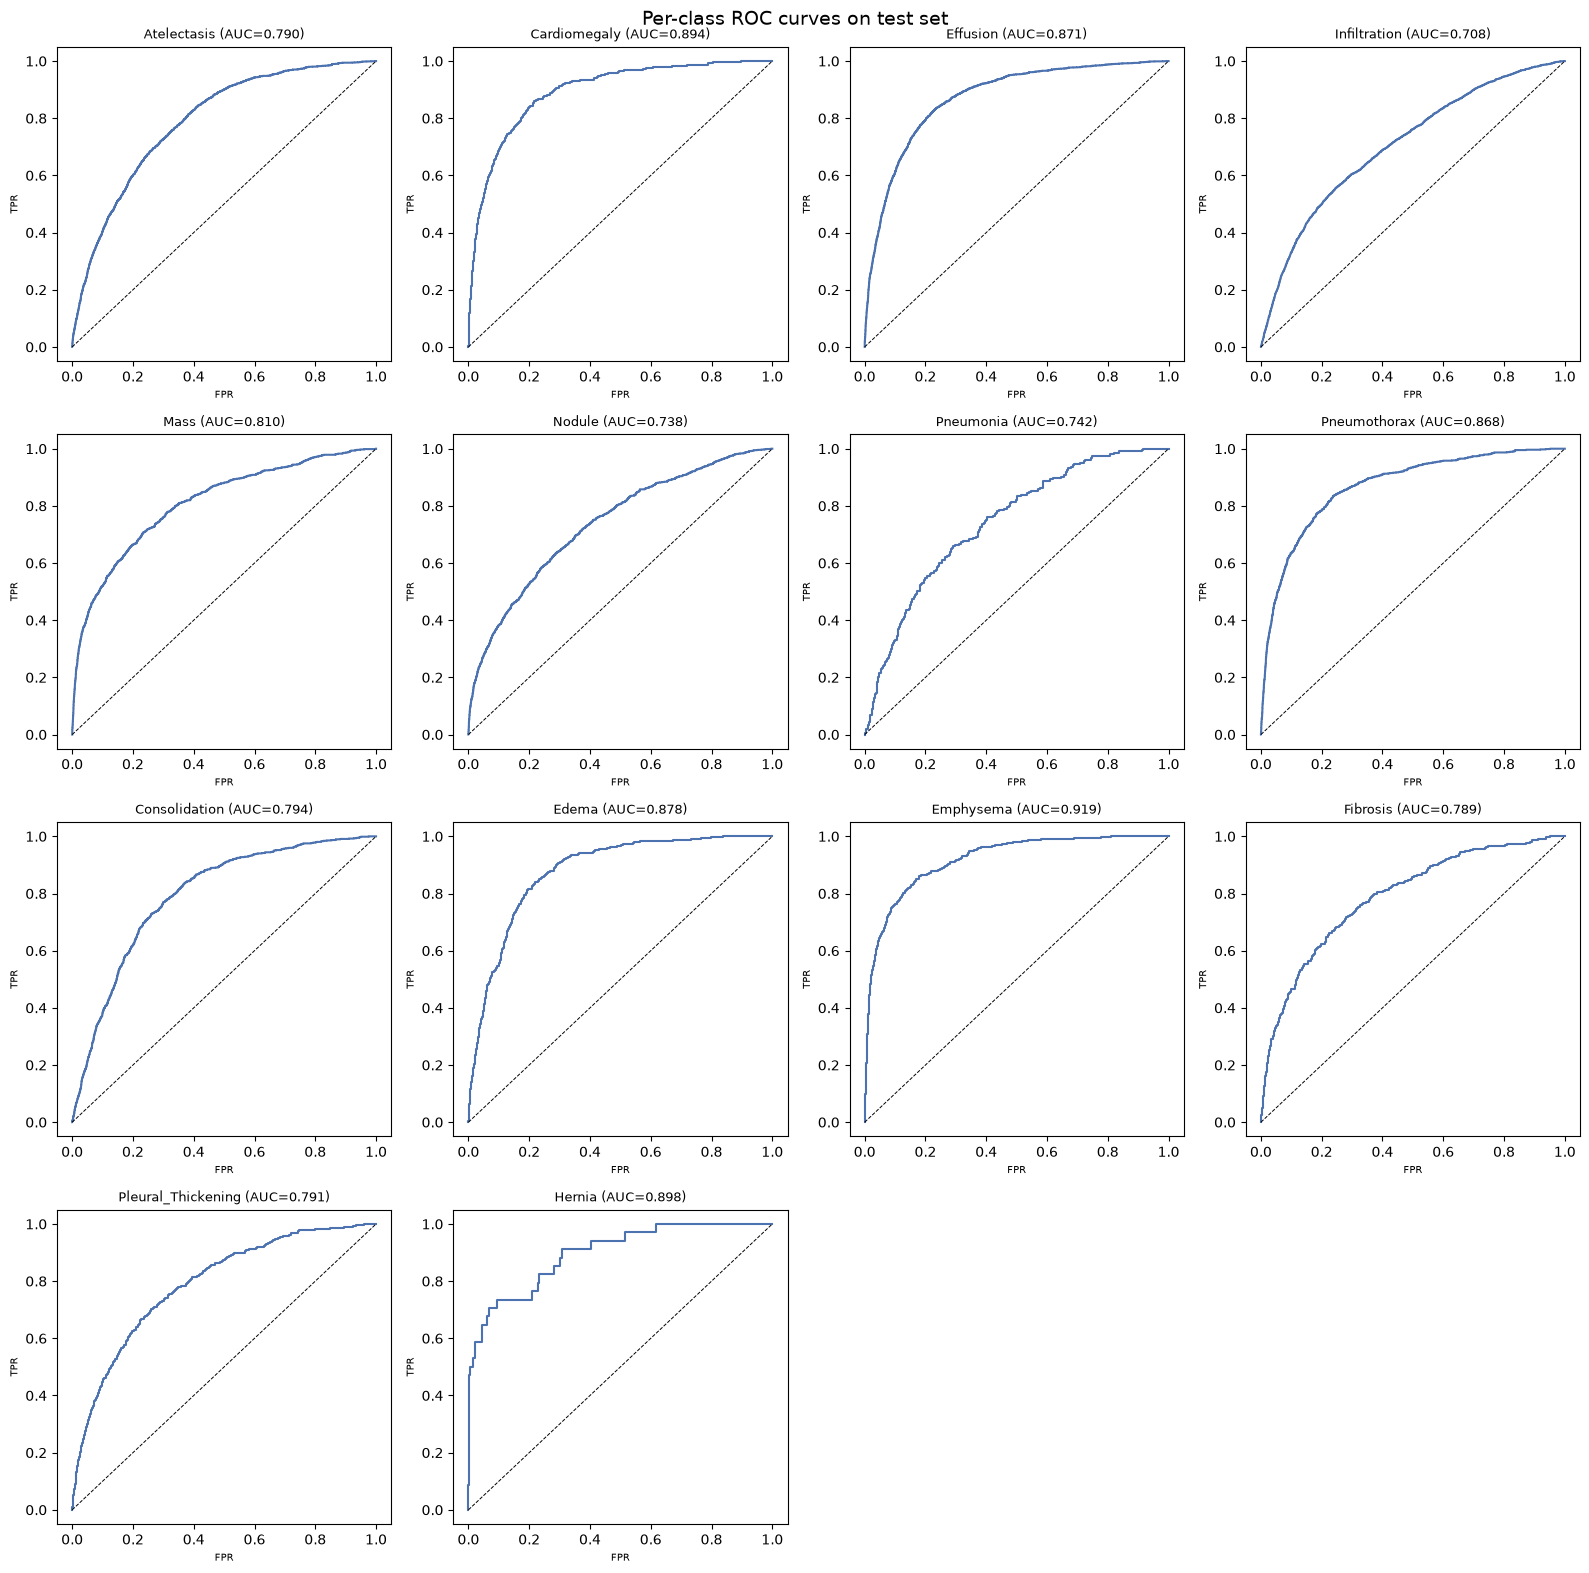

In [20]:

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for i, ax in enumerate(axes.flat):
    if i >= len(DISEASES):
        ax.axis("off")
        continue
    d = DISEASES[i]
    if len(np.unique(test_labels[:, i])) < 2:
        ax.set_title(f"{d}\n(no positive test samples)")
        ax.axis("off")
        continue
    fpr, tpr, _ = roc_curve(test_labels[:, i], test_probs[:, i])
    auc = roc_auc_score(test_labels[:, i], test_probs[:, i])
    ax.plot(fpr, tpr, color="#4C72B0")
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.7)
    ax.set_title(f"{d} (AUC={auc:.3f})", fontsize=9)
    ax.set_xlabel("FPR", fontsize=7); ax.set_ylabel("TPR", fontsize=7)
plt.suptitle("Per-class ROC curves on test set", fontsize=14)
plt.tight_layout()
plt.show()


## 14. Interactive UI — pick or upload a chest X-ray and see predictions

In [1]:
import ipywidgets as widgets
from IPython.display import display, clear_output

test_options = [(f"{os.path.basename(p)}", p) for p in test_df["filepath"].sample(
    min(50, len(test_df)), random_state=1
)]

image_dropdown = widgets.Dropdown(options=test_options, description="Test image:", style={"description_width": "initial"})
upload_widget = widgets.FileUpload(accept="image/*", multiple=False, description="Or upload")
predict_button = widgets.Button(description="Predict", button_style="success", icon="stethoscope")
output_area = widgets.Output()

def run_prediction(image_path=None, image_bytes=None):
    with output_area:
        clear_output(wait=True)
        if image_bytes is not None:
            arr = np.frombuffer(image_bytes, dtype=np.uint8)
            raw = cv2.imdecode(arr, cv2.IMREAD_COLOR)
            title = "Uploaded image"
        else:
            raw = cv2.imread(image_path)
            title = os.path.basename(image_path)

        processed = clahe_unsharp(raw)
        pil_img = Image.fromarray(cv2.cvtColor(processed, cv2.COLOR_BGR2RGB))
        img_t = val_ds.transform(pil_img).unsqueeze(0).to(DEVICE)  # eval-time transform, no augmentation

        # Top predicted disease (highest probability), used as the Grad-CAM target
        model.eval()
        with torch.no_grad():
            probs_preview = torch.sigmoid(model(img_t)).cpu().numpy()[0]
        top_idx = int(np.argmax(probs_preview))

        # Grad-CAM needs gradients, so this call is NOT wrapped in torch.no_grad()
        cam, probs = gradcam.generate(img_t, top_idx)
        overlay = overlay_heatmap(raw, cam)

        fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1, 1.3]})
        axes[0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB))
        axes[0].set_title(title)
        axes[0].axis("off")

        axes[1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        axes[1].set_title(f"Grad-CAM: {DISEASES[top_idx]}")
        axes[1].axis("off")

        order = np.argsort(probs)
        colors = ["#C44E52" if probs[i] >= 0.5 else "#4C72B0" for i in order]
        axes[2].barh([DISEASES[i] for i in order], probs[order], color=colors)
        axes[2].axvline(0.5, color="black", linestyle="--", linewidth=0.8)
        axes[2].set_xlim(0, 1)
        axes[2].set_title("Predicted disease probabilities")
        plt.tight_layout()
        plt.show()

        # --- Text summary: disease, live confidence, and the model's KNOWN test-set
        # performance for that disease (from Section 12 evaluation) ---
        top_disease = DISEASES[top_idx]
        top_conf = probs[top_idx]
        print(f"Most likely finding : {top_disease}  (confidence: {top_conf:.1%})")

        hits = [DISEASES[i] for i in range(14) if probs[i] >= 0.5]
        print("All findings >= 0.5 :", ", ".join(hits) if hits else "None (predicted: No Finding)")

        print("\nModel's known test-set performance per predicted disease:")
        shown = hits if hits else [top_disease]
        for d in shown:
            m = DISEASE_METRICS.get(d, {})
            auc = m.get("AUROC", float("nan"))
            acc = m.get("Accuracy", float("nan"))
            f1 = m.get("F1", float("nan"))
            auc_str = f"{auc:.3f}" if pd.notna(auc) else "n/a (too few positive test cases)"
            print(f"  {d:<20s} | Accuracy: {acc:.1%}  | AUROC: {auc_str}  | F1: {f1:.3f}" if pd.notna(f1)
                  else f"  {d:<20s} | Accuracy: {acc:.1%}  | AUROC: {auc_str}")

        print("\nGrad-CAM (red/yellow regions) shows which parts of the X-ray most")
        print(f"influenced the '{top_disease}' score — i.e. which image features the")
        print("DenseNet branch relied on for this prediction.")

def on_predict_clicked(_):
    if len(upload_widget.value) > 0:
        item = list(upload_widget.value.values())[0] if isinstance(upload_widget.value, dict) else upload_widget.value[0]
        content = item["content"] if isinstance(item, dict) else item.content
        run_prediction(image_bytes=bytes(content))
    else:
        run_prediction(image_path=image_dropdown.value)

predict_button.on_click(on_predict_clicked)

display(widgets.VBox([
    widgets.HTML("<b>Chest X-ray Disease Prediction — Interactive Demo</b>"),
    widgets.HBox([image_dropdown, upload_widget, predict_button]),
    output_area,
]))

# Auto-run once on the first dropdown option so the widget shows a result immediately
run_prediction(image_path=image_dropdown.value)


NameError: name 'test_df' is not defined


## 15. Notes for running on the college HPC (SLURM)

Example `job.sbatch`:

```bash
#!/bin/bash
#SBATCH --job-name=chestxray_dualbranch
#SBATCH --gres=gpu:1
#SBATCH --cpus-per-task=8
#SBATCH --mem=32G
#SBATCH --time=12:00:00
#SBATCH --output=logs/%x_%j.out

module load cuda/12.1 python/3.10
source ~/envs/chestxray/bin/activate

export KAGGLE_USERNAME=your_username
export KAGGLE_KEY=your_key

jupyter nbconvert --to notebook --execute --inplace chest_xray_dual_branch.ipynb
```

- `--execute --inplace` runs every cell and writes the outputs (plots, printed metrics) back into the `.ipynb` file, so you get a fully populated notebook with all the visual proof after the job finishes.
- Reduce `BATCH_SIZE` / `NUM_WORKERS` in the DataLoader cell if you hit GPU memory or CPU core limits on your allocation.
- Swap in the real MedMamba weights (see the model-definition cell) once you've confirmed the repo imports cleanly on the HPC's Python environment.
